# High-dimensional feature representations

Many feature representations you will work with will have more features than you can visualize at any single time.

It is tempting to use our 2D or 3D intuition to reason about points in high-dimensional spaces.

Here you can see some examples which show how this intuition may be misleading.



## Searching for your neighbors

In this example, assume N points are uniformly placed on a unit hypercube (line, square, cube etc).  

You are a point at the corner of this hypercube, and you want to find your neighbors. How far do you have to travel, for example to find just one neighbor?

For example, on a line of 1 km, with 100 people placed uniformly on it, on average you would to travel 0.01 km (covering 0.01 of the total volume) to find one neighbor. On a square of 1 by 1 km, you would need to travel 0.1 km in each direction to cover 0.01 of the total volume.

**Modify the code below to see what happens in more than 3 dimensions.**

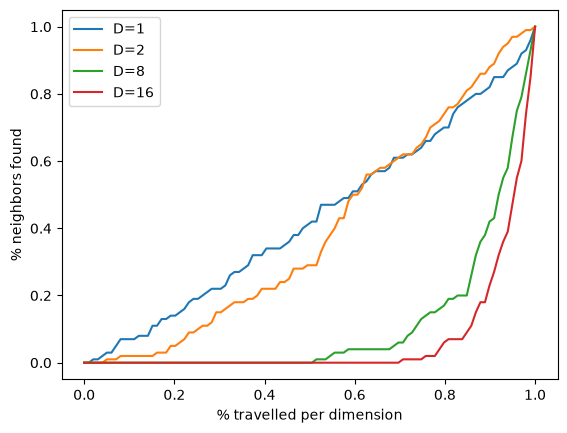

In [1]:
import numpy as np
import matplotlib.pyplot as plt

#How many dimensions the hypercube is in
dimensions = [1, 2, 8, 16]

#How many points are in the hypercube
N = 100

#How many steps do you want to divide each dimension in
steps = 100

#Generate coordinates you will travel to while searching
step_coords = np.linspace(0,1,steps, endpoint=True)

#Store how many neighbors you found
found_neighbors = np.zeros((len(dimensions), steps))

for j, D in enumerate(dimensions):

    #Generate N uniformly distributed points in D dimensions
    x = np.random.rand(N, D)

    #"Travel" a number of steps, and see how many points you encountered (in percentage)
    for i, s in enumerate(step_coords):
        found_neighbors[j,i] = np.sum(np.all(x < s, axis=1)) / N


    plt.plot(step_coords, found_neighbors[j,:], label=f'D={D}')
    plt.xlabel('% travelled per dimension')
    plt.ylabel('% neighbors found')
plt.legend()
plt.show()

In [2]:
# Exercise - can you find the %travelled per dimension to find 1% of the points analytically, without generating this data?

# Think about the formula for calculating the volume of a cube

import numpy as np

dimensions = [1, 2, 4, 16]

#travel=

#print(travel)


## Distances in high dimensional spaces

The example above might be counterintuitive - it would mean that most points live in the corners of the hypercube!

Here is an example to verify this. Let us generate uniformly distributed points again, and look at their distances to each other.

Think of points on a line, and their distances to each all other points. There will be a lot of small distances (any point to its neighbors), and few large distances (corner points to each other).

**Modify the code below to understand what happens in high dimensions.**






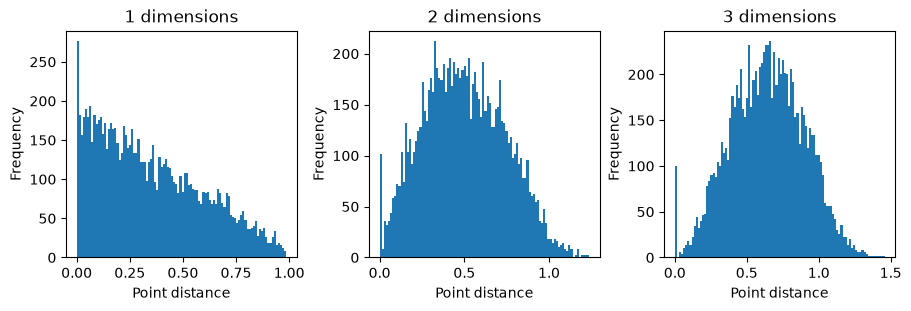

In [3]:
import numpy as np
import matplotlib.pyplot as plt


#How many points are in the hypercube
N = 100

#How many dimensions
dimensions = [1, 2, 3]

fig, axes = plt.subplots(ncols=len(dimensions), nrows=1, constrained_layout=True, figsize=(len(dimensions)*3, 3))

for i, D in enumerate(dimensions):
    #Generate points
    x = np.random.rand(N,D)

    #Calculate the pairwise Euclidean distance matrix
    dist = np.sqrt(np.sum((x[None,:,:] - x[:,None,:])**2, -1))

    #Put into a vector
    dist_vec = dist.ravel()

    #Plot histogram
    axes[i].hist(dist_vec, bins=100)
    axes[i].set_xlabel("Point distance")
    axes[i].set_ylabel("Frequency")
    axes[i].set_title(f'{D} dimensions')
plt.show()


## Exercise with real-world data

Hopefully this example shows that in high dimensions, the Euclidean distances between points become almost the same! When does that happen? When all points live in the corners.

Another piece of intuition that might help, is if you studied the law of large numbers in a statistics course, and you look at the equation for Euclidean distance - it is a sum over many dimensions.

The goal of this exercise is to verify whether real-world data behaves in a similar way. You can use the MNIST digit dataset which has 784 dimensions (similar in size to some typical image features).

**Explore the distances in the MNIST dataset. Do the distances behave in a similar way to randomly generated data? What does this mean?**

In [4]:
#Get the dataset
from sklearn.datasets import fetch_openml
x_digits, y = fetch_openml('mnist_784', version=1, return_X_y=True)

In [5]:
#Exercise: explore the distances & compare them to the generated data above


